# Two identical sites on the ligand, with cooperativity: multi-cycle kinetics (MCK)

Parameter-recovery benchmark. This notebook is AI generated, and has been reviewed by Osvaldo Burastero.

The data are simulated from the rate equations written below, integrated with SciPy (`solve_ivp`, Radau). No pykingenie function is used to make the data. The data are then fitted with pykingenie, using one Smax (Rmax) shared by all curves, and the fitted parameters are compared with the true ones. A parameter counts as recovered when its relative error is at most 5%.

Gaussian noise with a standard deviation of 0.5 RU is added, 1% of Rmax (50 RU). This is at the high end of real instruments: reference-subtracted SPR data typically show 0.1-0.5 RU of noise, and BLI 0.3-1% of a typical binding signal.


## Model

As the two-site model, but binding to the second site is changed by the cooperativity factor $\sigma$: its dissociation constant is $K_d/\sigma$. pykingenie splits the effect evenly between the rates, $k_{on,2} = \sqrt{\sigma}\,k_{on}$ and $k_{off,2} = k_{off}/\sqrt{\sigma}$, and the simulation uses the same split (the kinetics depend on it, the equilibrium does not):

$$\frac{df_{PL}}{dt} = 2k_{on}C f_P - k_{off} f_{PL} - \sqrt{\sigma}\,k_{on} C f_{PL} + \frac{2k_{off}}{\sqrt{\sigma}} f_{LPL}$$

$$\frac{df_{LPL}}{dt} = \sqrt{\sigma}\,k_{on} C f_{PL} - \frac{2k_{off}}{\sqrt{\sigma}} f_{LPL}$$

$$\text{signal} = R_{max,PL}\,f_{PL} + R_{max,LPL}\,f_{LPL}$$

Here $\sigma = 4$ (positive cooperativity).

pykingenie reports `Kd [µM]` and `k_off [1/s]` of the first site, `sigma`, `Rmax_PL` and `Rmax_LPL`.

In [1]:
import sys

import numpy as np

sys.path.insert(0, '..')
from benchmark_helpers import simulate_mck, compare_parameters, plot_fit
from pykingenie.fitter_surface import KineticsFitter

## True parameters and experiment design

Each concentration is injected on a regenerated (free) surface for 300 s, followed by 600 s of buffer. Sampling every 1 s.

In [2]:
params = dict(kon=1.0, koff=0.01, sigma=4.0, Rmax_PL=25.0, Rmax_LPL=50.0)
concs = [0.0011, 0.0033, 0.01, 0.03, 0.09, 0.27]  # µM, Kd of the first site = 0.01 µM

true_values = {'Kd': params['koff'] / params['kon'], 'k_off': params['koff'], 'sigma': params['sigma'],
               'Rmax_PL': params['Rmax_PL'], 'Rmax_LPL': params['Rmax_LPL']}

## Rate equations (first principles)

In [3]:
def rhs(t, y, conc, p):
    fPL, fLPL = y
    fP = 1 - fPL - fLPL
    s = np.sqrt(p['sigma'])
    dfPL = (2 * p['kon'] * conc * fP - p['koff'] * fPL
            - s * p['kon'] * conc * fPL + 2 * p['koff'] / s * fLPL)
    dfLPL = s * p['kon'] * conc * fPL - 2 * p['koff'] / s * fLPL
    return [dfPL, dfLPL]


def signal(y, p):
    return p['Rmax_PL'] * y[:, 0] + p['Rmax_LPL'] * y[:, 1]


y0 = [0.0, 0.0]

## Simulate the data

In [4]:
data = simulate_mck(rhs, signal, y0, params, concs, assoc_time=300.0, disso_time=600.0, dt=1.0,
                    noise_sd=0.5, seed=0)

## Fit with pykingenie

One Smax shared by all curves (`smax_id` is 0 for every curve).

In [5]:
fitter = KineticsFitter(
    time_assoc_lst=data['time_assoc'], association_signal_lst=data['assoc'],
    lig_conc_lst=concs,
    time_diss_lst=data['time_disso'], dissociation_signal_lst=data['disso'],
    smax_id=[0] * len(concs), name_lst=['benchmark'], is_single_cycle=False,
)
fitter.get_steady_state()
fitter.fit_steady_state()  # starting value of Kd
fitter.fit_two_site_assoc_and_disso(shared_smax=True, fit_sigma=True)
fitter.fit_params_kinetics

,Kd [µM],k_off [1/s],Rmax_PL,Rmax_LPL,sigma,(Derived) k_on [1/µM/s]
0,0.009923,0.009929,24.806632,50.049364,3.951856,1.000641


## Compare with the true parameters

In [6]:
df = fitter.fit_params_kinetics
fitted_values = {'Kd': fitter.Kd, 'k_off': fitter.k_off, 'sigma': df['sigma'].iloc[0],
                 'Rmax_PL': df['Rmax_PL'].iloc[0], 'Rmax_LPL': df['Rmax_LPL'].iloc[0]}

comparison = compare_parameters(true_values, fitted_values, rtol=0.05)
worst = comparison['rel. error (%)'].abs().idxmax()
print(f"All parameters recovered within 5%: {comparison['recovered'].all()}. "
      f"Largest error: {comparison.loc[worst, 'rel. error (%)']:+.2f}% ({worst})")
comparison

All parameters recovered within 5%: True. Largest error: -1.20% (sigma)


,true,fitted,rel. error (%),recovered
parameter,,,,
Kd,0.01,0.009923,-0.770406,True
k_off,0.01,0.009929,-0.706831,True
sigma,4.00,3.951856,-1.203604,True
Rmax_PL,25.00,24.806632,-0.773471,True
Rmax_LPL,50.00,50.049364,0.098727,True


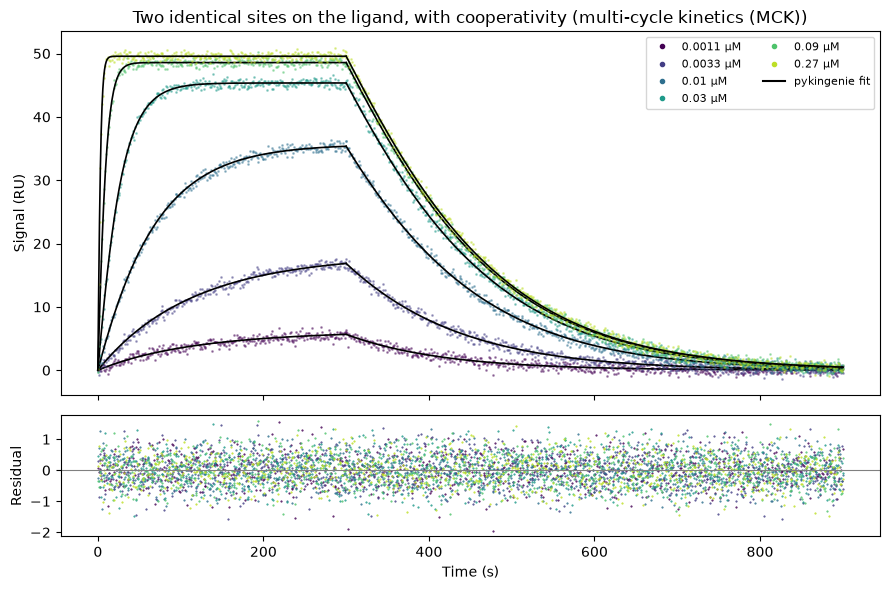

In [7]:
fig = plot_fit(data, fitter, concs, 'Two identical sites on the ligand, with cooperativity (multi-cycle kinetics (MCK))')